# Figure 2 — panels (young and old fibroblasts stimulated with TGF-β under tension)
Draws every Figure 2 / Supplementary Figure 2Sa / 2Sb panel from the tables in `data/` (written by `tgfb_analysis.ipynb`)
→ `figures/<panel>.svg` (2d also `.pdf`; 2Sb also `.png`), named by final panel letter. Panel 2a is the hand-drawn schematic
`data/fig2a_schematic.svg`. Pages are assembled in `tgfb_pages.ipynb`. Sections follow the analyses; each final panel
has its own header. Needs `pygraphviz` and `pdftocairo`.

In [1]:
import json
import subprocess

import matplotlib
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.transforms import blended_transform_factory

# Arial, base font 16, text kept as text in SVG/PDF (editable in Illustrator)
plt.rcParams.update({'font.size': 16})
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']
plt.rcParams["text.usetex"] = False
plt.rcParams["svg.fonttype"] = "none"
plt.rcParams["pdf.fonttype"] = 42

DATA = "data"
FIG = "figures"
young_select_pathways = ['Extracellular matrix (Reactome)',
                         'TGF-beta signaling (KEGG+Reactome)',
                         'Senescence inhibitors (CellAge)',
                         'MYC targets v1 (H)']
PATHWAY_KEYS = dict(zip(young_select_pathways, ["ecm", "tgfb", "seninh", "myc"]))

# contact-state colours: young blue, old red, shared green (graph edges); "other" genes grey
edge_cpal = {'Young': sns.color_palette()[0],
             'Old': sns.color_palette()[3],
             'Shared': sns.color_palette("Paired")[2]}
hue_cpal = {"Forms Young only contacts": edge_cpal['Young'],
            "Other contacts": '#9c9c9c',
            "Forms Old only contacts": edge_cpal['Old']}

## Expression
### Supplementary Figure 2Sa, panel a — Expression of all genes per condition
log10(mean count + 1) per condition; dashed line = the active-gene threshold (100 counts).

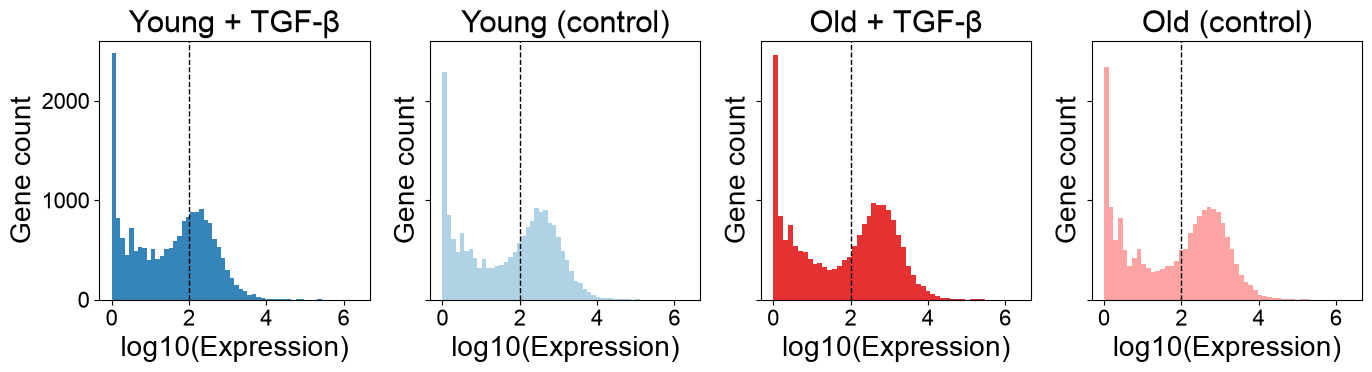

In [2]:
expression = pd.read_csv(f"{DATA}/expression_tgfb.csv", index_col=0)
ring_cpal = {"Upreg ORT": sns.color_palette("Paired")[5],
             "Upreg ORC": sns.color_palette("Paired")[4],
             "Upreg YRT": sns.color_palette("Paired")[1],
             "Upreg YRC": sns.color_palette("Paired")[0]}
cond_to_text = {'YRT': 'Young + TGF-β', 'YRC': 'Young (control)', 'ORT': 'Old + TGF-β', 'ORC': 'Old (control)'}
conditions = ['YRT_avg', 'YRC_avg', 'ORT_avg', 'ORC_avg']

fig, axes = plt.subplots(1, 4, figsize=(14, 4), sharex=True, sharey=True)
threshold = np.log10(100)
for ax, cond in zip(axes.flatten(), conditions):
    expr = np.log10(expression[cond] + 1)              # pseudocount 1 avoids log(0)
    ax.hist(expr, bins=50, color=ring_cpal[f"Upreg {cond.split('_')[0]}"], alpha=0.9)
    ax.axvline(threshold, linestyle='--', color='black', linewidth=1)
    ax.set_title(cond_to_text[cond.replace('_avg', '')], fontsize=22)
    ax.set_xlabel('log10(Expression)', fontsize=20)
    ax.set_ylabel('Gene count', fontsize=20)
plt.tight_layout()
plt.savefig(f'{FIG}/fig2Sa_a_expression_histograms.svg', bbox_inches='tight')
plt.show()

## Gene-level contact graphs
Gene-level graphs of each pathway's subsets (`data/gene_graphs/`): nodes coloured by chromosome, edges by contact state
(young-only and old-only edges drawn on top), graphviz layout.

In [3]:
def load_gene_graph(pathway, subset):
    """Rebuild a saved gene graph with its original node and edge order (the layout depends on it)."""
    stem = f"{DATA}/gene_graphs/{PATHWAY_KEYS[pathway]}_{subset}"
    nodes = pd.read_csv(f"{stem}_nodes.csv")
    edges = pd.read_csv(f"{stem}_edges.csv")
    G = nx.Graph()
    for gene, chrom in zip(nodes.gene, nodes.chrom):
        G.add_node(gene, chrom=chrom)
    for gene1, gene2, edge_type in zip(edges.gene1, edges.gene2, edges.edge_type):
        G.add_edge(gene1, gene2, edge_type=edge_type)
    return G


def plot_graph(G, edge_cpal=None, overlay_edge_types=[], node_label_attr='pathway_genes_with_tss',
               ax=None, fontsize=24, edge_width=0.5):
    """Draw a graph with nodes coloured by chromosome and edges by edge type (overlay types drawn on top).
    The loaded gene graphs have no 'pathway_genes_with_tss' attribute, so no node labels are drawn (as published)."""
    chroms = [f'chr{n}' for n in range(1, 23)] + ['chrX', 'chrY', 'chrM']
    hex_colors = ["#1F78B4", "#33A02C", "#E31A1C", "#FF7F00", "#6A3D9A", "#B15928",
                  "#1B9E77", "#E7298A", "#66A61E", "#E6AB02", "#666666", "#A6CEE3",
                  "#B2DF8A", "#FB9A99", "#FDBF6F", "#CAB2D6", "#83d5af", "#ff69b4",
                  "#b249d5", "#7edc45", "#c497cf", "#594e50", "#d3c4a8", "#c17e7f", "#5f7b35"]
    chrom_cpal = dict(zip(chroms, hex_colors))
    node_colors = [chrom_cpal[c] for c in nx.get_node_attributes(G, 'chrom').values()]
    if edge_cpal is None:
        edge_cpal = dict(zip(set(nx.get_edge_attributes(G, 'edge_type').values()), sns.color_palette()))
    if ax is None:
        fig, ax = plt.subplots(1, 1, figsize=(15, 15))
    else:
        fig = ax.figure

    pos = nx.nx_agraph.graphviz_layout(G)
    x_vals, y_vals = zip(*pos.values())
    x_margin = (max(x_vals) - min(x_vals)) * 0.15
    y_margin = (max(y_vals) - min(y_vals)) * 0.15
    ax.set_xlim(min(x_vals) - x_margin, max(x_vals) + x_margin)
    ax.set_ylim(min(y_vals) - y_margin, max(y_vals) + y_margin)

    if node_label_attr is None:
        labels_dict = dict(zip(G.nodes, G.nodes))
    else:
        labels_dict = {k: ', '.join(v) for k, v in nx.get_node_attributes(G, node_label_attr).items()}

    edge_attrs = nx.get_edge_attributes(G, 'edge_type')
    if len(overlay_edge_types) == 0:
        edge_colors = [edge_cpal[edge_attrs[e]] for e in G.edges]
        nx.draw(G, pos=pos, labels=labels_dict, node_color=node_colors,
                edge_color=edge_colors, ax=ax, font_size=fontsize, width=edge_width)
    else:
        overlay_edges = [e for e, t in edge_attrs.items() if t in overlay_edge_types]
        other_edges = [e for e in G.edges if e not in overlay_edges]
        other_edge_colors = [edge_cpal[edge_attrs[e]] for e in other_edges]
        nx.draw(G, pos=pos, labels=labels_dict, node_color=node_colors,
                edgelist=other_edges, edge_color=other_edge_colors, ax=ax,
                font_size=fontsize, width=edge_width)
        overlay_edge_colors = [edge_cpal[edge_attrs[e]] for e in overlay_edges]
        nx.draw_networkx_edges(G, pos, edgelist=overlay_edges, edge_color=overlay_edge_colors,
                               ax=ax, width=edge_width)

    # chromosome legend for the chromosomes present
    unique_colors = np.unique(node_colors)
    chrom_list = [k for k, v in chrom_cpal.items() if v in unique_colors]
    node_legend_patches = [mpatches.Patch(color=chrom_cpal[chrom], label=chrom) for chrom in chrom_list]
    ax.legend(handles=node_legend_patches, bbox_to_anchor=(1, 0.5), loc='center left', fontsize=fontsize)
    plt.tight_layout()
    return fig, ax


SUBSETS = ['young_only', 'young_other', 'old_only', 'old_other']   # young-specific | other | old-specific | other

### Figure 2b — Extracellular matrix pathway contact graphs

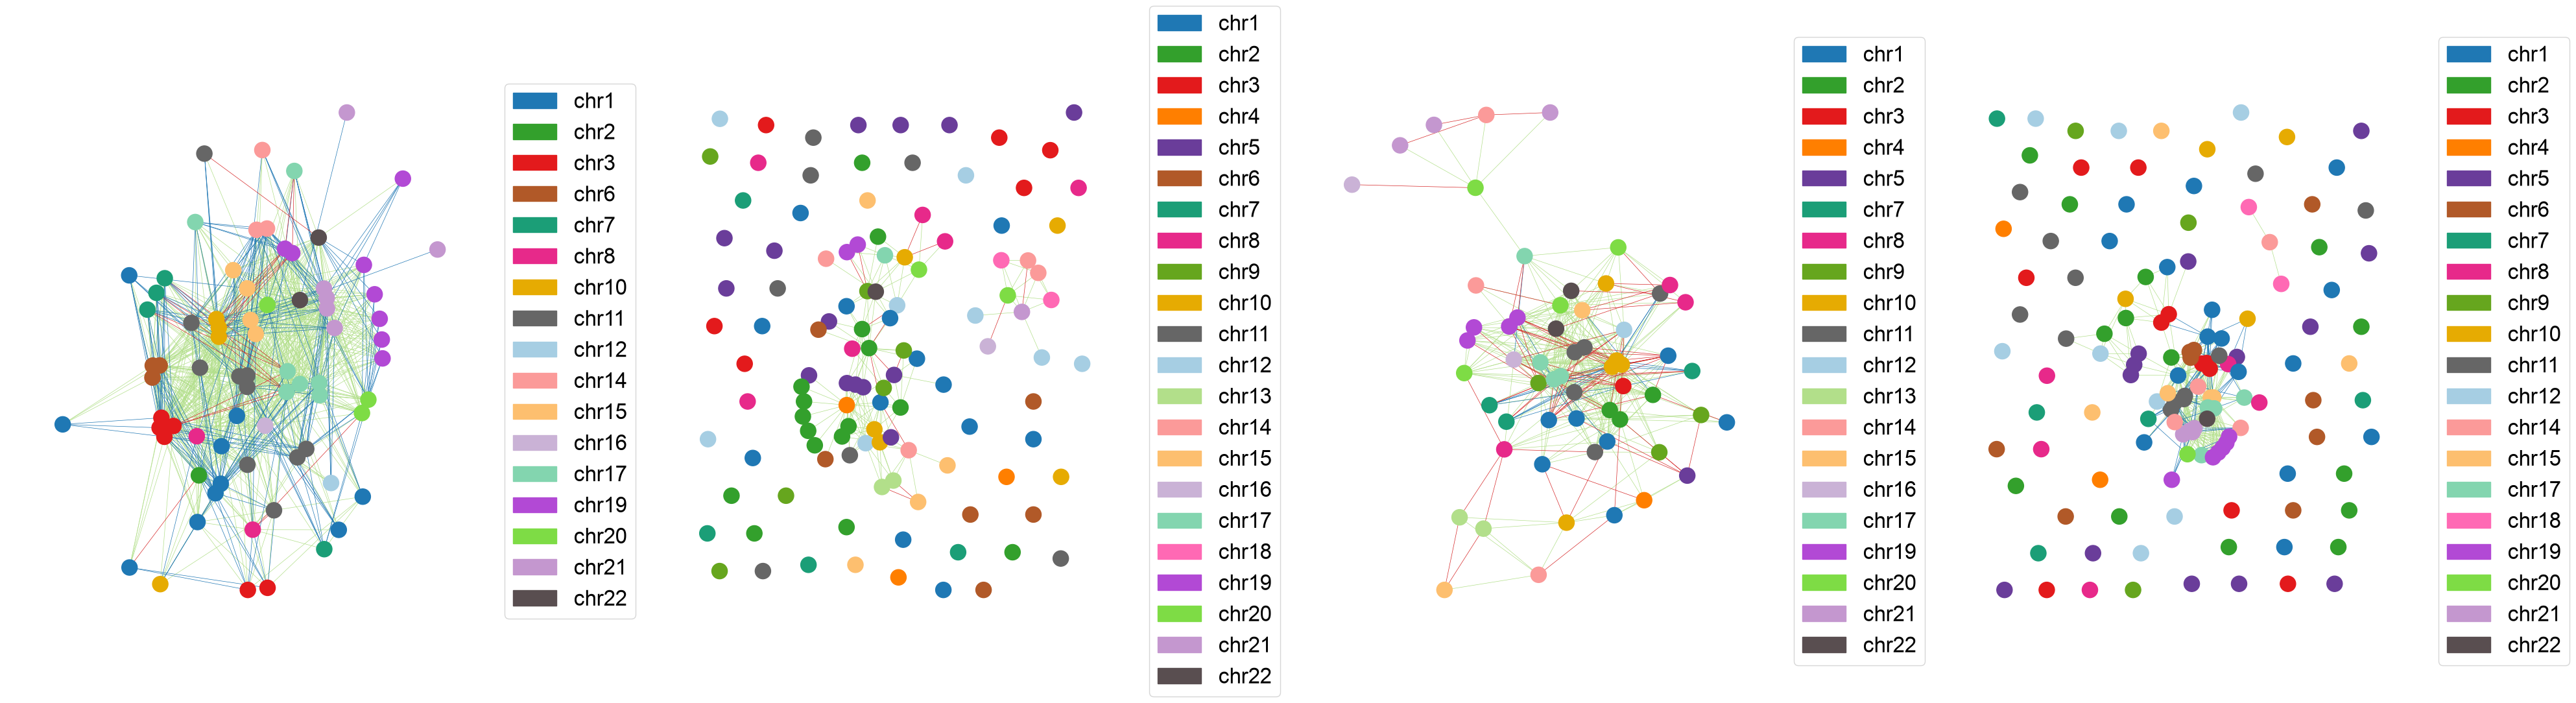

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(40, 11))
for i, subset in enumerate(SUBSETS):
    G_gene = load_gene_graph('Extracellular matrix (Reactome)', subset)
    plot_graph(G_gene, edge_cpal, ax=axes[i], overlay_edge_types=['Old', 'Young'], fontsize=24)
plt.tight_layout()
plt.savefig(f'{FIG}/fig2b_ecm_contact_graphs.svg', bbox_inches='tight')
plt.show()

### Supplementary Figure 2Sa, panel b — Contact graphs of the other three young-colocalized pathways

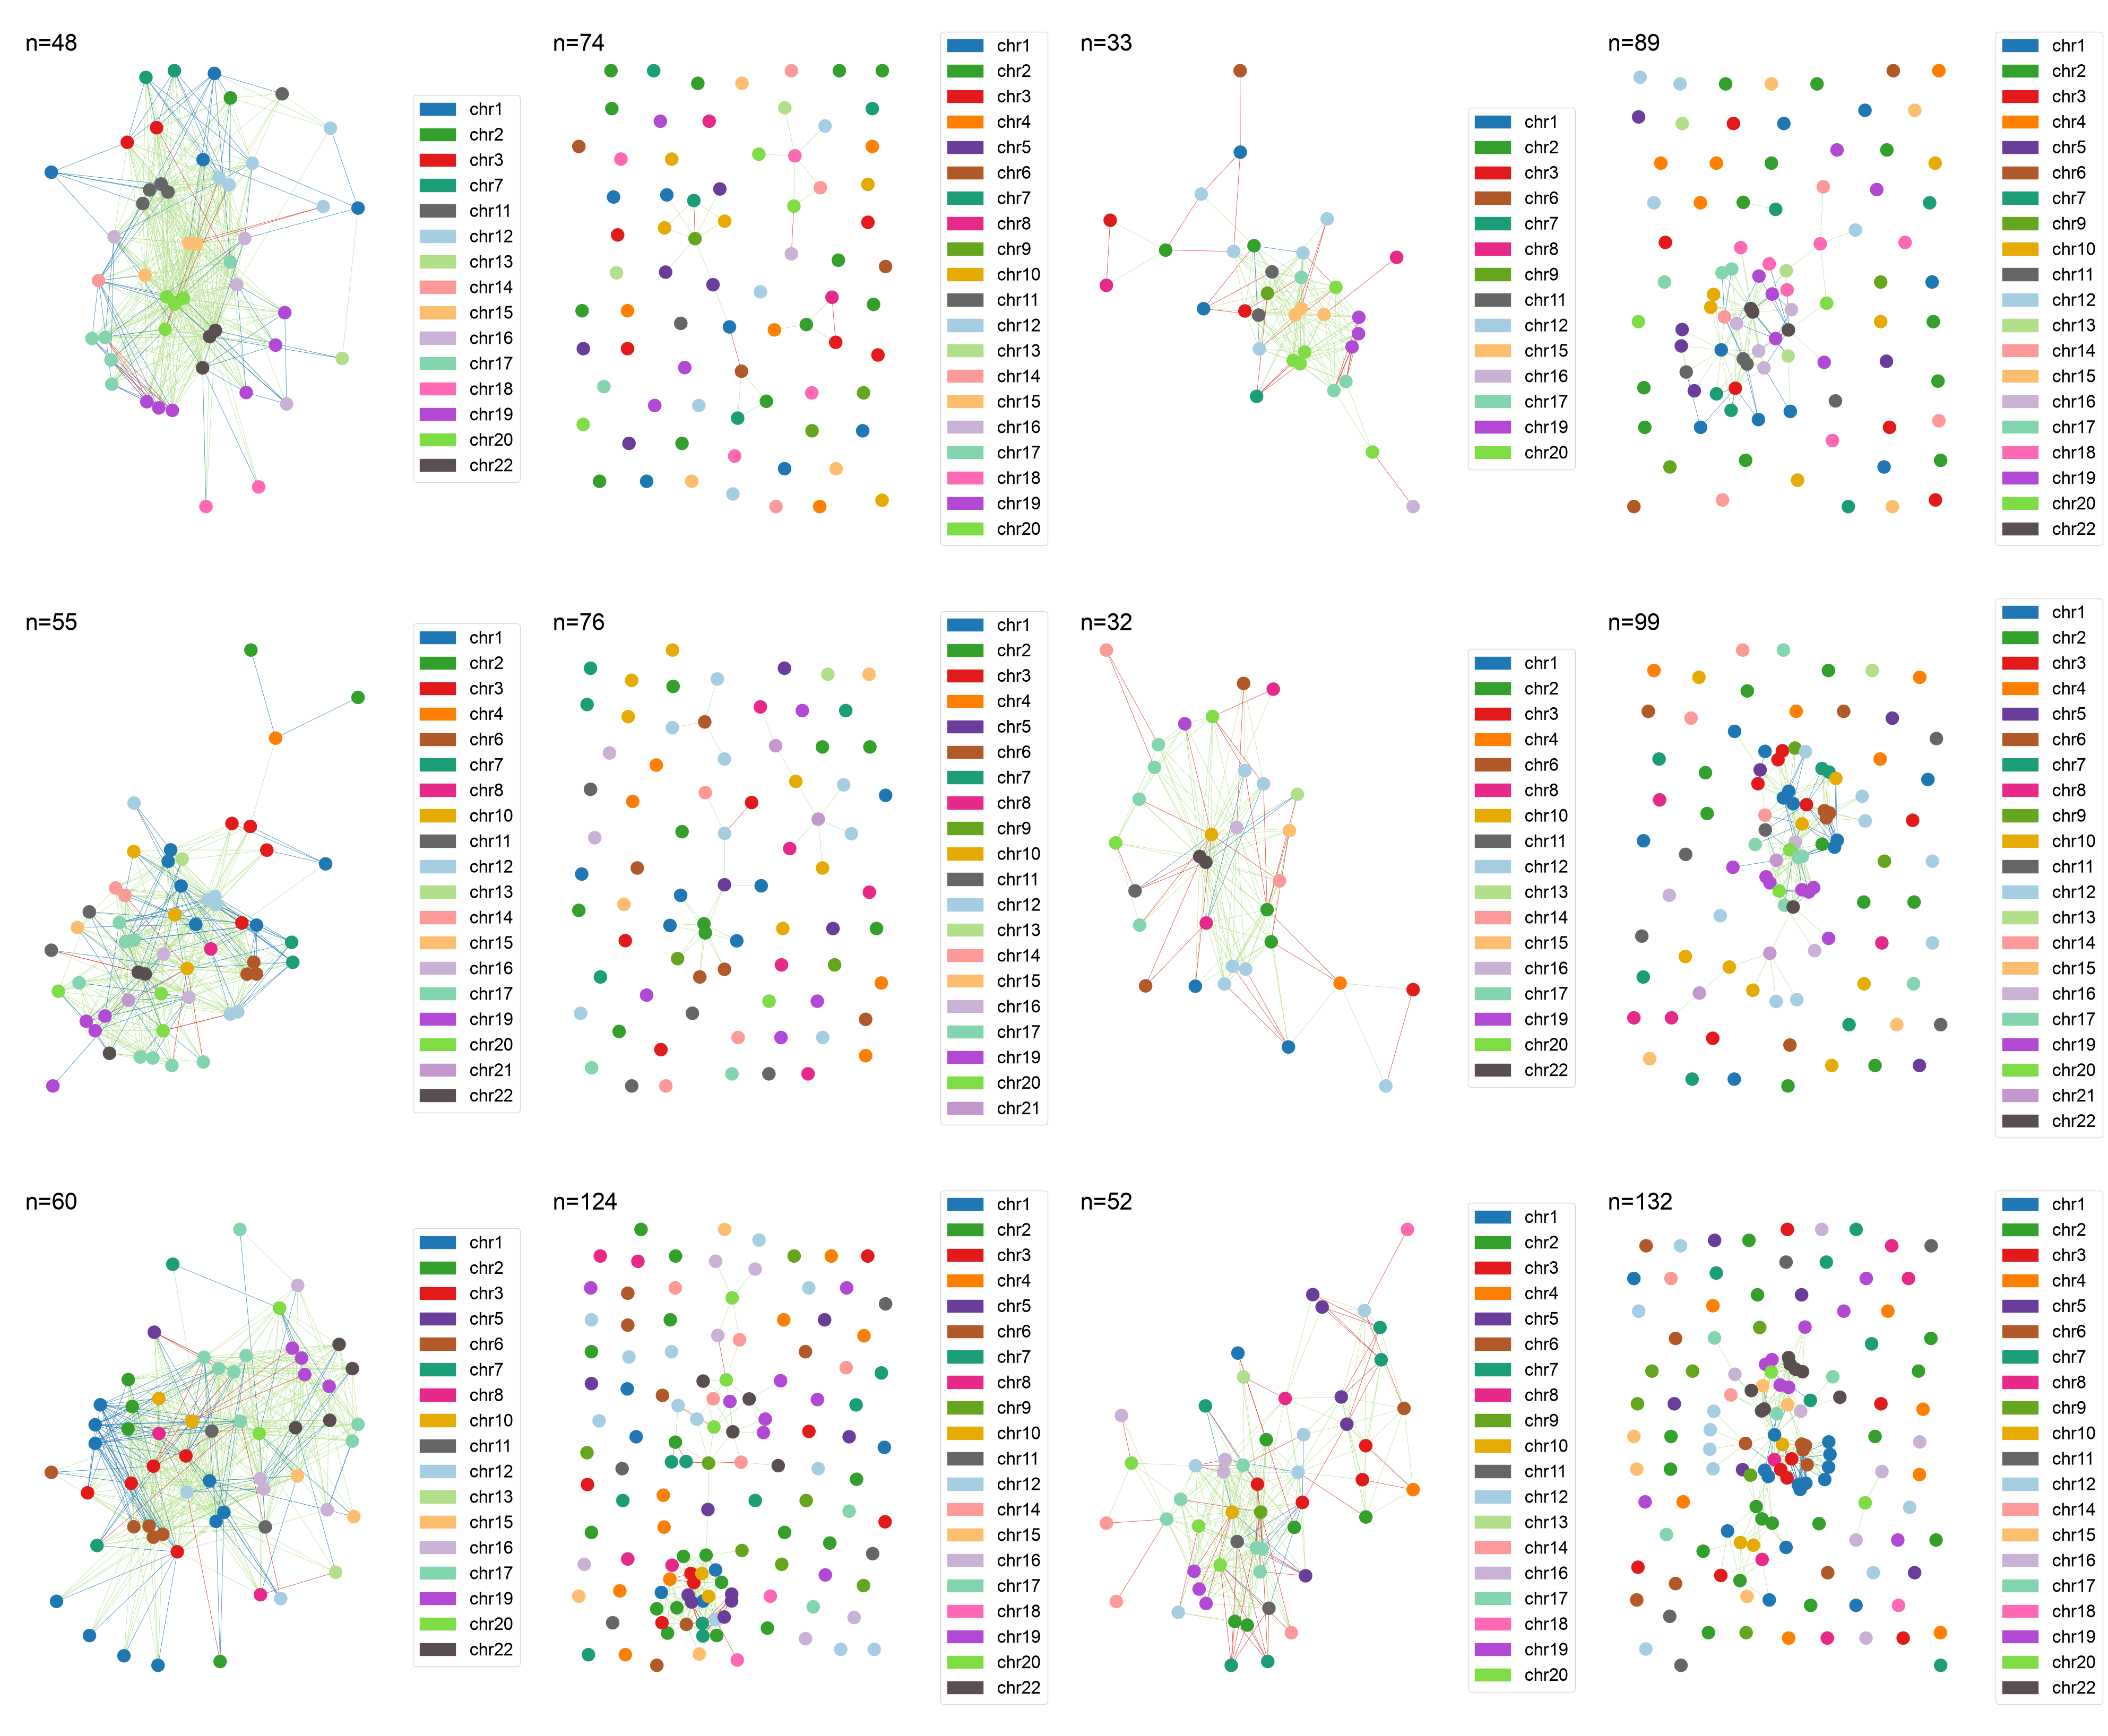

In [5]:
other_pathways = young_select_pathways[1:]
fig, axes = plt.subplots(len(other_pathways), 4, figsize=(40, 11 * len(other_pathways)))
for row, pathway in enumerate(other_pathways):
    for col, subset in enumerate(SUBSETS):
        G_gene = load_gene_graph(pathway, subset)
        ax = axes[row][col]
        plot_graph(G_gene, edge_cpal, ax=ax, overlay_edge_types=['Old', 'Young'], fontsize=24)
        ax.text(0.05, 0.95, f'n={G_gene.number_of_nodes()}', transform=ax.transAxes, fontsize=32, va='top', ha='left')
plt.tight_layout()
plt.savefig(f'{FIG}/fig2Sa_b_contact_graphs.svg', bbox_inches='tight')
plt.show()

#### Edge-type legend for Figure 2b and Supplementary Figure 2Sa, panel b
Placed next to the graphs by `tgfb_pages.ipynb`.

In [6]:
EDGE = {"Young only": edge_cpal['Young'], "Old only": edge_cpal['Old'], "Shared": edge_cpal['Shared']}
with plt.rc_context({"font.size": 10}):                # base font 10 (matplotlib default), as the page's small text
    fig, ax = plt.subplots(figsize=(1.6, 1.0))
    ax.axis("off")
    ax.legend(handles=[Line2D([], [], color=c, lw=2, label=k) for k, c in EDGE.items()], title="Edge type", loc="center",
              frameon=True, edgecolor="#BBBBBB", fontsize=9, title_fontsize=9.5, handlelength=1.6)
    fig.savefig(f"{FIG}/fig2_legend_edge_types.svg", bbox_inches="tight")
    plt.close(fig)

## TGF-β response by contact class
### Figure 2c — TGF-β response of genes forming age-specific contacts vs other genes
Kernel density of log2FC (TGF-β vs control): rows = young cells split by young-specific contacts, old cells split by
young-specific contacts, old cells split by old-specific contacts; p = two-sided Mann–Whitney (`data/fig2c_mannwhitney.csv`).

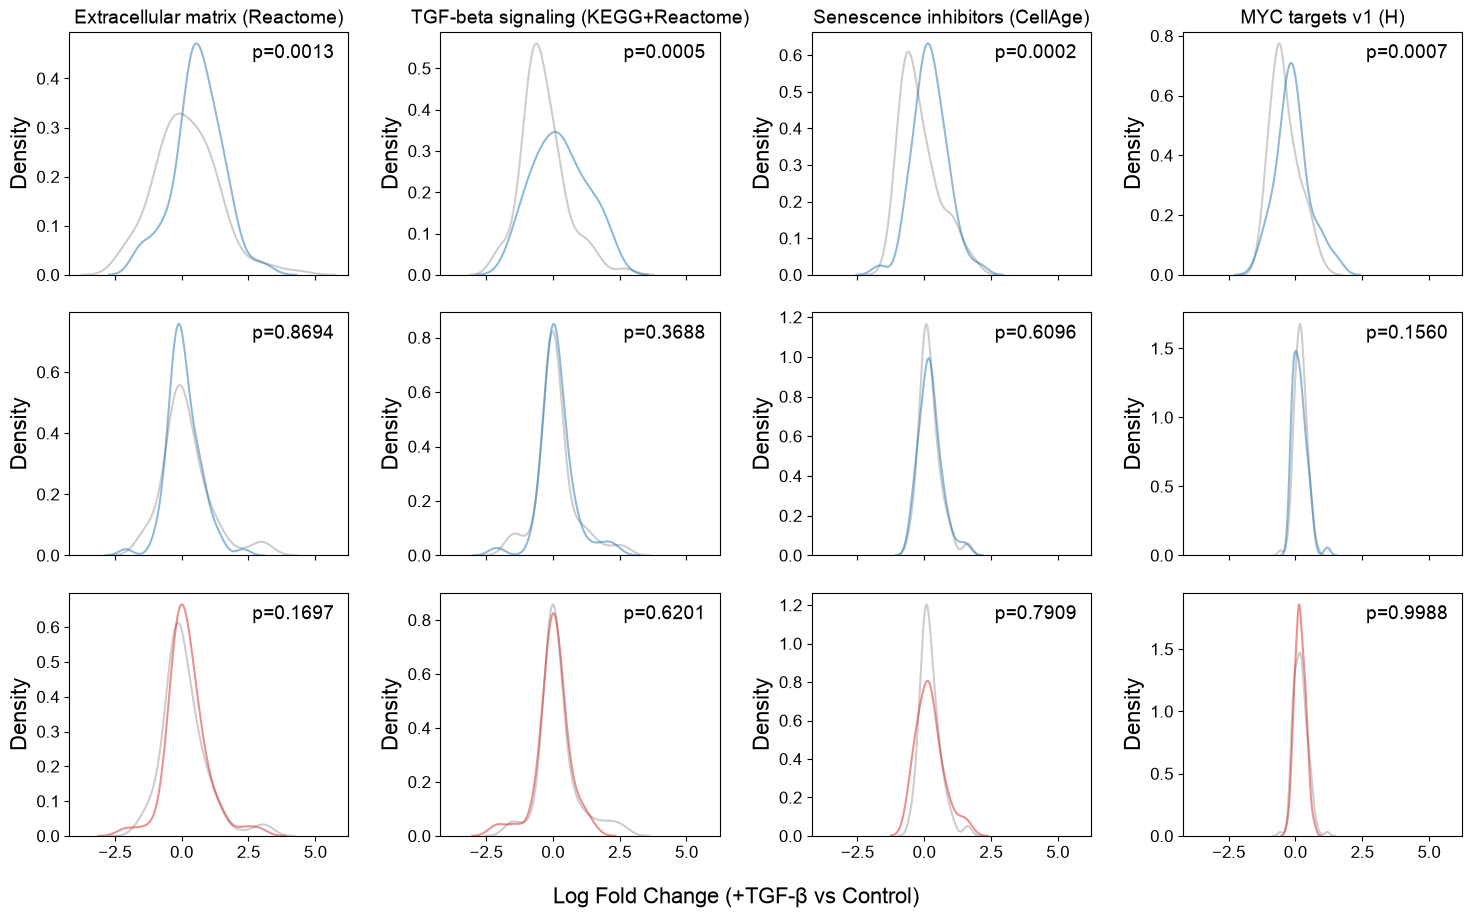

In [7]:
contacts = pd.read_csv(f"{DATA}/pathway_gene_contacts.csv")
kde_tests = pd.read_csv(f"{DATA}/fig2c_mannwhitney.csv")

fig, axes = plt.subplots(3, len(young_select_pathways), figsize=(15, 9), sharex=True)
for col, pathway in enumerate(young_select_pathways):
    temp = contacts[contacts.pathway == pathway].copy()
    temp['Contact Type Young'] = np.where(temp.young_contact, 'Forms Young only contacts', 'Other contacts')
    temp['Contact Type Old'] = np.where(temp.old_contact, 'Forms Old only contacts', 'Other contacts')

    temp_young = temp.sort_values('Contact Type Young')
    sns.kdeplot(data=temp_young, x='YRT_vs_YRC_lfc', hue='Contact Type Young',          # row 0: young cells
                palette=hue_cpal, ax=axes[0][col], alpha=0.5, common_norm=False)
    axes[0][col].set_title(pathway, fontsize=14)
    sns.kdeplot(data=temp_young, x='ORT_vs_ORC_lfc', hue='Contact Type Young',          # row 1: old cells
                palette=hue_cpal, ax=axes[1][col], alpha=0.5, common_norm=False)
    temp_old = temp.sort_values('Contact Type Old')
    sns.kdeplot(data=temp_old, x='ORT_vs_ORC_lfc', hue='Contact Type Old',              # row 2: old cells, old contacts
                palette=hue_cpal, ax=axes[2][col], alpha=0.5, common_norm=False)

    for _, test in kde_tests[kde_tests.pathway == pathway].iterrows():
        axes[test.row][col].text(0.95, 0.95, f'p={test.p:.4f}', transform=axes[test.row][col].transAxes,
                                 fontsize=14, va='top', ha='right')
    for ax in axes[:, col]:
        ax.set_xlabel('')
        ax.set_ylabel('Density', fontsize=16)
        ax.tick_params(axis='both', labelsize=12)
        if ax.get_legend():
            ax.get_legend().remove()
plt.tight_layout()
fig.text(0.5, -0.02, 'Log Fold Change (+TGF-β vs Control)', ha='center', fontsize=16)
plt.savefig(f'{FIG}/fig2c_tgfb_response.svg', bbox_inches='tight')
plt.show()

## Promoter accessibility
### Figure 2d — Promoter accessibility of young-specific vs other genes (young fibroblasts)
Share of active pathway genes with a promoter peak (± 1 kb of the TSS) in control (solid) and TGF-β (hatched)
(`data/fig2d_promoter_accessibility.csv`). Saved as PDF and converted to SVG with `pdftocairo`, which keeps the hatching.

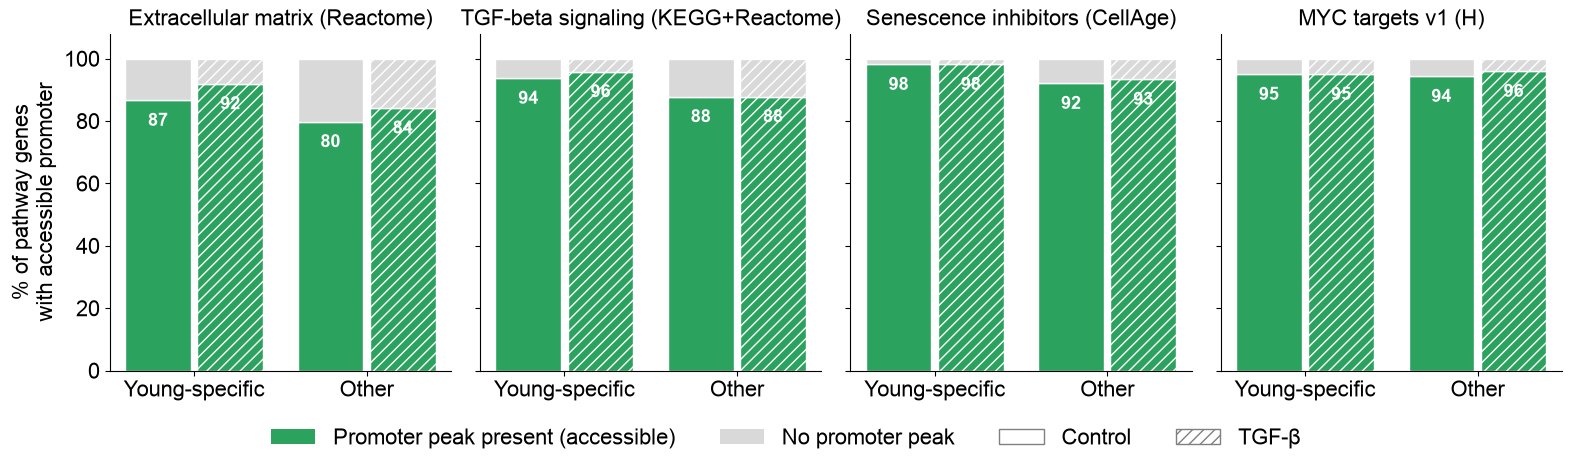

CompletedProcess(args=['pdftocairo', '-svg', 'figures/fig2d_promoter_accessibility.pdf', 'figures/fig2d_promoter_accessibility.svg'], returncode=0)

In [8]:
accessibility = pd.read_csv(f"{DATA}/fig2d_promoter_accessibility.csv")
c_accessible = '#2CA25F'
c_no_peak = '#D9D9D9'
group_x = {'Young-specific': 0.0, 'Other': 1.05}        # two contact-class groups per pathway
cond_off = {'Control': -0.22, 'TGF-β': 0.22}            # a control and a TGF-β bar within each group
bar_w = 0.4

fig, axes = plt.subplots(1, len(young_select_pathways), figsize=(16, 4.4), sharey=True)
for ax, pathway in zip(axes, young_select_pathways):
    for _, r in accessibility[accessibility.pathway == pathway].iterrows():
        x = group_x[r.contact] + cond_off[r.condition]
        frac_acc = r.n_accessible / r.n_genes if r.n_genes else 0
        hatch = '///' if r.condition == 'TGF-β' else None
        ax.bar(x, frac_acc * 100, width=bar_w, color=c_accessible, edgecolor='white', hatch=hatch)
        ax.bar(x, (1 - frac_acc) * 100, bottom=frac_acc * 100, width=bar_w, color=c_no_peak, edgecolor='white',
               hatch=hatch)
        ax.text(x, frac_acc * 100 - 4, f'{frac_acc * 100:.0f}', ha='center', va='top', fontsize=13, color='white',
                fontweight='bold')
    ax.set_xticks([group_x['Young-specific'], group_x['Other']])
    ax.set_xticklabels(['Young-specific', 'Other'], fontsize=16)
    ax.set_ylim(0, 108)
    ax.set_title(pathway, fontsize=16)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('% of pathway genes\nwith accessible promoter', fontsize=16)
legend_elements = [Patch(facecolor=c_accessible, label='Promoter peak present (accessible)'),
                   Patch(facecolor=c_no_peak, label='No promoter peak'),
                   Patch(facecolor='white', edgecolor='grey', label='Control'),
                   Patch(facecolor='white', edgecolor='grey', hatch='///', label='TGF-β')]
fig.legend(handles=legend_elements, loc='lower center', ncol=4, fontsize=16, frameon=False, bbox_to_anchor=(0.5, -0.10))
plt.tight_layout()
plt.savefig(f'{FIG}/fig2d_promoter_accessibility.pdf', bbox_inches='tight')
plt.show()
subprocess.run(["pdftocairo", "-svg", f"{FIG}/fig2d_promoter_accessibility.pdf", f"{FIG}/fig2d_promoter_accessibility.svg"],
               check=True)

## Promoter peak changes under TGF-β
### Supplementary Figure 2Sa, panel c — Promoter peak change under TGF-β (young fibroblasts)
Gene-level DESeq2 log2FC of promoter peaks (TGF-β vs control), young-specific vs other genes; stars = Mann–Whitney,
BH-adjusted over the 8 pathway × age tests (`data/fig2Sa_c_promoter_peak_de*.csv`).

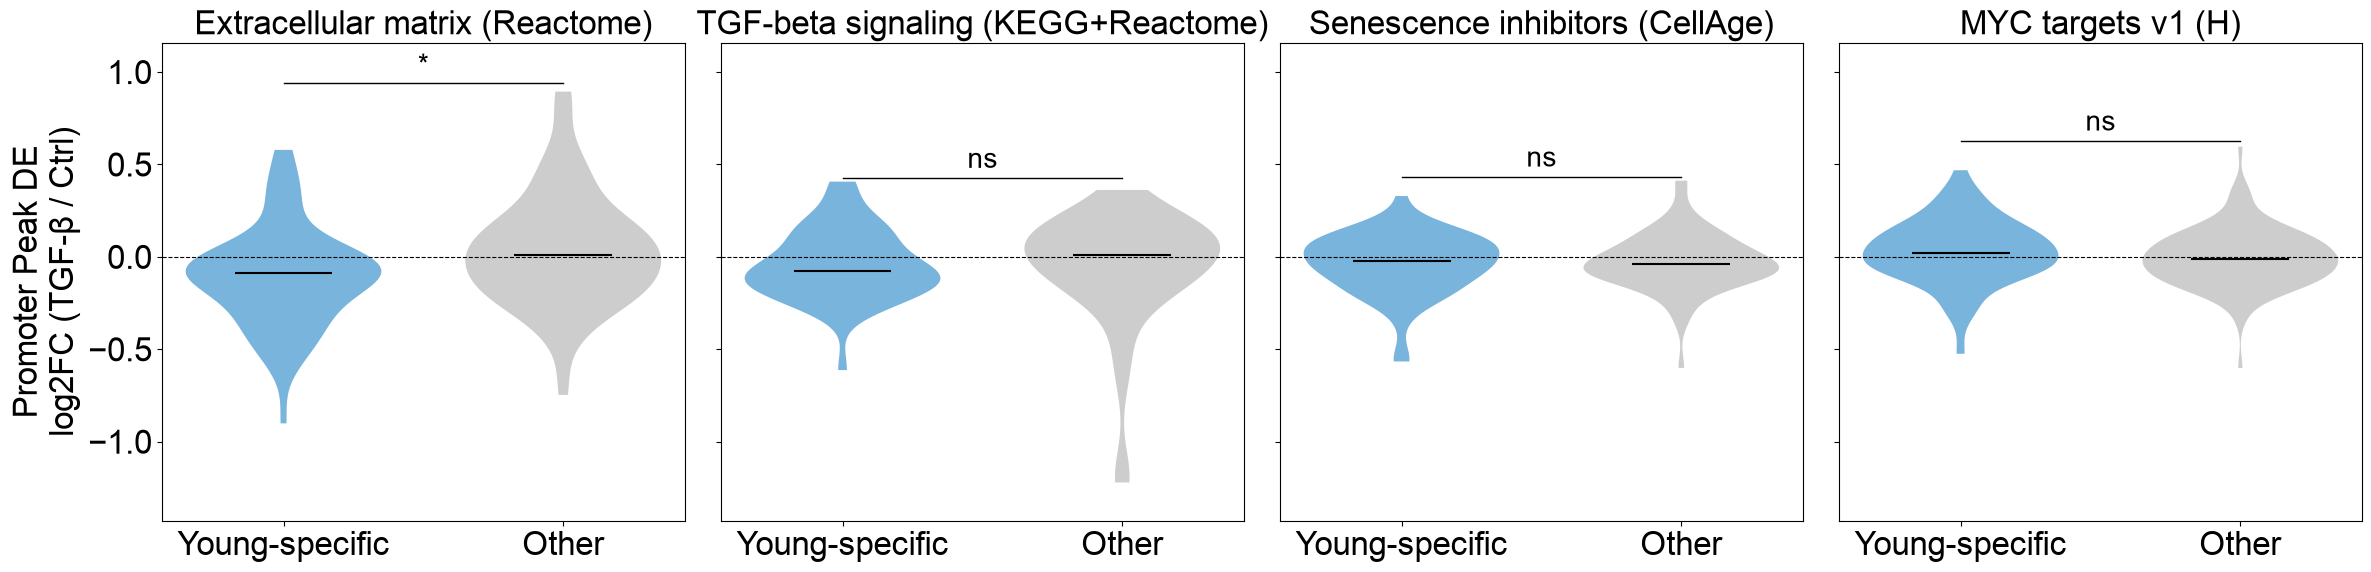

In [9]:
records_df = pd.read_csv(f"{DATA}/fig2Sa_c_promoter_peak_de.csv")
stats_df = pd.read_csv(f"{DATA}/fig2Sa_c_promoter_peak_de_stats.csv")
fdr_lookup = stats_df.set_index(['pathway', 'age'])['fdr'].to_dict()


def stars(p):
    """Significance stars for an adjusted p-value."""
    if np.isnan(p):
        return 'ns'
    if p < 0.001:
        return '***'
    if p < 0.01:
        return '**'
    if p < 0.05:
        return '*'
    return 'ns'


contact_cpal = {'Young-specific': '#4C9BD1', 'Other': '#BDBDBD'}
positions = {'Young-specific': 1, 'Other': 2}
n_path = len(young_select_pathways)
fig, axes = plt.subplots(1, n_path, figsize=(6 * n_path, 6), sharey=True)
for col, pathway in enumerate(young_select_pathways):
    ax = axes[col]
    sub = records_df[(records_df['pathway'] == pathway) & (records_df['age'] == 'young')]
    group_vals = {}
    for contact in ['Young-specific', 'Other']:
        vals = sub.loc[sub['contact'] == contact, 'mean_log2fc'].dropna().to_numpy()
        group_vals[contact] = vals
        if len(vals) == 0:
            continue
        vp = ax.violinplot(vals, positions=[positions[contact]], widths=0.7, showmedians=True, showextrema=False)
        for body in vp['bodies']:
            body.set_facecolor(contact_cpal[contact])
            body.set_alpha(0.75)
            body.set_edgecolor('none')
        vp['cmedians'].set_color('black')
        vp['cmedians'].set_linewidth(1.5)
    ax.axhline(0, color='k', linestyle='--', linewidth=0.8)

    # significance bar above both violins, with padding so it fits
    yc_vals = group_vals['Young-specific']
    ot_vals = group_vals['Other']
    if len(yc_vals) > 0 and len(ot_vals) > 0:
        fdr = fdr_lookup[(pathway, 'young')]
        y_bar = max(yc_vals.max(), ot_vals.max()) * 1.05
        ymin, ymax = ax.get_ylim()
        ymax = max(ymax, y_bar)
        yrange = ymax - ymin
        ax.set_ylim(ymin - 0.05 * yrange, ymax + 0.02 * yrange)
        ymin, ymax = ax.get_ylim()
        yrange = ymax - ymin
        ax.plot([1, 2], [y_bar, y_bar], color='k', linewidth=1)
        ax.text(1.5, y_bar + 0.01 * yrange, stars(fdr), ha='center', va='bottom', fontsize=20)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(['Young-specific', 'Other'], fontsize=24)
    ax.tick_params(axis='y', labelsize=24)
    ax.set_title(pathway, fontsize=24)
axes[0].set_ylabel('Promoter Peak DE\nlog2FC (TGF-β / Ctrl)', fontsize=24)
plt.tight_layout()
plt.savefig(f'{FIG}/fig2Sa_c_promoter_peak_de.svg', bbox_inches='tight')
plt.show()

## Locus gene density and contact groups
Active pathway genes at loci with no detected interchromosomal contact, with other contacts only, or with young-specific
contacts (`data/fig2Sb_gene_groups.csv`); p = two-sided Mann–Whitney, young-specific vs other contacts
(`data/fig2Sb_mannwhitney.csv`). These two panels use the Figure 1 house style (base font 11, Arial math text).

In [10]:
gene_groups = pd.read_csv(f"{DATA}/fig2Sb_gene_groups.csv")
group_tests = pd.read_csv(f"{DATA}/fig2Sb_mannwhitney.csv")
SB_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
            "legend.fontsize": 10, "mathtext.fontset": "custom", "mathtext.rm": "Arial", "mathtext.it": "Arial:italic",
            "mathtext.bf": "Arial:bold"}
GROUPS = [("no_contact", "No detected contact", "#D9D9D9"), ("other_contact", "Other contacts", "#9E9E9E"),
          ("young_contact", "Young-specific contacts", "#1f77b4")]
SHORT = {'Extracellular matrix (Reactome)': "Extracellular matrix", 'TGF-beta signaling (KEGG+Reactome)': "TGF-β signaling",
         'Senescence inhibitors (CellAge)': "Senescence inhibitors", 'MYC targets v1 (H)': "MYC targets v1"}
W = 0.26                                               # violin spacing within a pathway


def group_violins(ax, values_of, p_of, ymax_text):
    """Per pathway, one violin per contact group (median bar) and the young-specific vs other p above them."""
    for i, pathway in enumerate(young_select_pathways):
        sub = gene_groups[gene_groups.pathway == pathway]
        for k, (grp, _, col) in enumerate(GROUPS):
            x = i + (k - 1) * W
            v = values_of(sub[sub.group == grp])
            parts = ax.violinplot(v, positions=[x], widths=W * 0.95, showextrema=False, bw_method=0.35)
            for b in parts["bodies"]:
                b.set_facecolor(col)
                b.set_edgecolor("black")
                b.set_linewidth(0.5)
                b.set_alpha(1)
            ax.hlines(np.median(v), x - W * 0.22, x + W * 0.22, color="white" if grp == "young_contact" else "black", lw=1.6)
        p = p_of(pathway)
        ax.plot([i, i + W], [ymax_text, ymax_text], color="black", lw=0.8)
        ax.text(i + W / 2, ymax_text + 0.05, f"p = {p:.1e}" if p < 0.001 else f"p = {p:.3f}", ha="center", va="bottom",
                fontsize=8)


def group_legend(fig, ax):
    """Framed contact-group legend, centred under the plot area."""
    fig.legend(handles=[Patch(facecolor=c, edgecolor="black", lw=0.5, label=lab) for _, lab, c in GROUPS],
               loc="lower center", bbox_to_anchor=(0.5, 0), bbox_transform=blended_transform_factory(ax.transAxes, fig.transFigure),
               ncol=3, frameon=True, edgecolor="black", fontsize=8.5)


def test_p(pathway, value):
    """Mann-Whitney p (young-specific vs other contacts) for one pathway and value."""
    return group_tests[(group_tests.pathway == pathway) & (group_tests.value == value)].p.iloc[0]

### Supplementary Figure 2Sb, panel a — Locus gene density by contact group

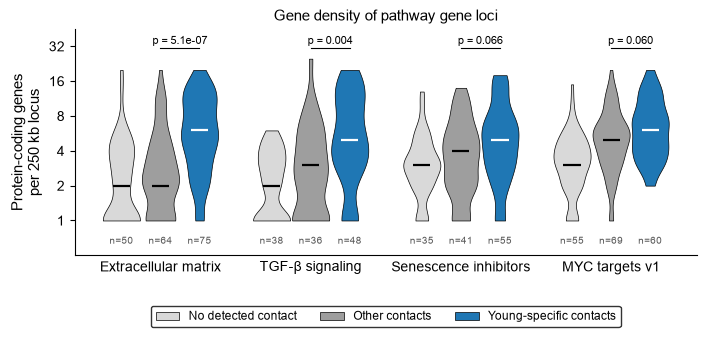

In [11]:
with plt.rc_context(SB_STYLE):
    H = 3.4
    fig, ax = plt.subplots(figsize=(7.2, H))
    group_violins(ax, lambda d: np.log2(d.genes_in_locus), lambda pw: test_p(pw, 'genes_in_locus'), 4.95)
    for i, pathway in enumerate(young_select_pathways):              # group sizes under the violins
        sub = gene_groups[gene_groups.pathway == pathway]
        for k, (grp, _, _) in enumerate(GROUPS):
            ax.text(i + (k - 1) * W, -0.45, f"n={(sub.group == grp).sum()}", ha="center", va="top", fontsize=7.5, color="0.35")
    ax.set_xticks(range(len(young_select_pathways)), [SHORT[p] for p in young_select_pathways])
    ax.tick_params(axis="x", length=0, pad=4)
    ax.set_yticks(range(0, 6), [str(2 ** k) for k in range(0, 6)])
    ax.set_ylim(-1.0, 5.5)
    ax.set_ylabel("Protein-coding genes\nper 250 kb locus")
    ax.set_title("Gene density of pathway gene loci", fontsize=11)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
    group_legend(fig, ax)
    fig.tight_layout(rect=(0, 0.42 / H, 1, 1))
    fig.savefig(f"{FIG}/fig2Sb_a_gene_density.svg", bbox_inches="tight")
    fig.savefig(f"{FIG}/fig2Sb_a_gene_density.png", dpi=200, bbox_inches="tight")
    plt.show()

### Supplementary Figure 2Sb, panel b — TGF-β response by contact group, young vs old fibroblasts

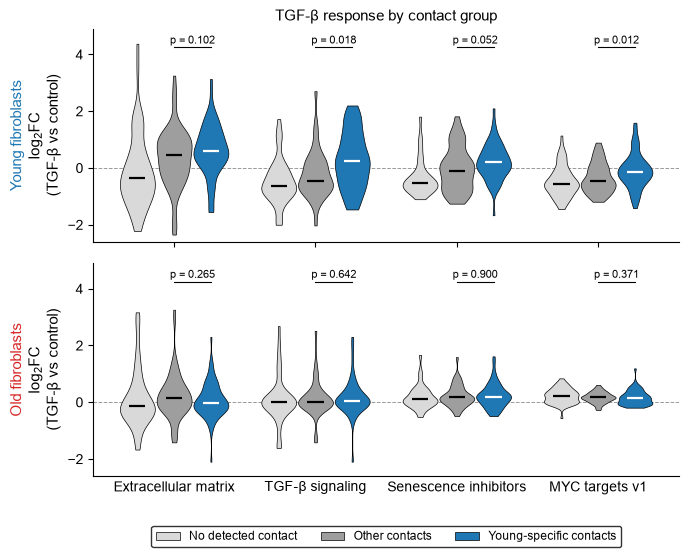

In [12]:
YOUNG_C, OLD_C = "#1f77b4", "#d62728"
with plt.rc_context(SB_STYLE):
    H = 5.6
    fig, axes = plt.subplots(2, 1, figsize=(7.2, H), sharex=True)
    for ax, (lfc, row_label, row_col) in zip(axes, (("YRT_vs_YRC_lfc", "Young fibroblasts", YOUNG_C),
                                                     ("ORT_vs_ORC_lfc", "Old fibroblasts", OLD_C))):
        group_violins(ax, lambda d, c=lfc: d[c], lambda pw, c=lfc: test_p(pw, c), 4.25)
        ax.axhline(0, color="0.6", lw=0.7, ls="--", zorder=0)
        ax.set_ylim(-2.6, 4.9)
        ax.set_ylabel("log$_2$FC\n(TGF-β vs control)")
        ax.text(-0.13, 0.5, row_label, transform=ax.transAxes, rotation=90, ha="center", va="center", fontsize=11,
                color=row_col)
        for sp in ("top", "right"):
            ax.spines[sp].set_visible(False)
    axes[1].set_xticks(range(len(young_select_pathways)), [SHORT[p] for p in young_select_pathways])
    axes[1].tick_params(axis="x", length=0)
    axes[0].set_title("TGF-β response by contact group", fontsize=11)
    group_legend(fig, axes[1])
    fig.tight_layout(rect=(0.03, 0.42 / H, 1, 1))
    fig.savefig(f"{FIG}/fig2Sb_b_response_by_contact_group.svg", bbox_inches="tight")
    fig.savefig(f"{FIG}/fig2Sb_b_response_by_contact_group.png", dpi=200, bbox_inches="tight")
    plt.show()